# 06. Pipeline Unificado de Inferência de Calçadas (Curitiba)

Este notebook demonstra a utilização do **`SidewalkPipeline`** (`scripts.inferencia`), o módulo oficial de inferência de ponta a ponta para:
1. **Classificação de Qualidade Viária**: Modelo binário de alto valor operacional (*Transitável* vs *Crítica*) ou 3 classes (*Adequada*, *Inadequada Geral*, *Não id.*).
2. **Explicabilidade e Diagnóstico Físico**: Avaliação simultânea de 11 tags de defeito (trincas, ondulações, desníveis, vegetação invasora, buracos severos), com atenuação calibrada de falsos-positivos em calçadas históricas de *petit-pavé*.

### Casos de Uso Suportados:
* **Imagem Única** (arquivos locais, PIL Images ou arrays NumPy em memória para APIs/UIs).
* **Lote de Imagens** (listas de fotos para processamento em paralelo).
* **Diretório Completo** (varredura automática de pastas de imagens coletadas no Street View com exportação para CSV/JSON).

In [1]:
import sys, os
import glob
import matplotlib.pyplot as plt
from PIL import Image

# Adiciona a raiz do projeto ao path
sys.path.append(os.path.abspath(".."))
from scripts.inferencia import SidewalkPipeline, inferir_calcadas
from scripts.utils.device import get_device

device = get_device()
print(f"Dispositivo de aceleração detectado: {device}")

C:\Users\caduo\dev\APx-2026.2-Task2-Producao-de-dados-de-qualidade-e-tipologia-de-calcadas\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo de aceleração detectado: privateuseone:0


C:\Users\caduo\dev\APx-2026.2-Task2-Producao-de-dados-de-qualidade-e-tipologia-de-calcadas\scripts\utils\dinov2\layers\swiglu_ffn.py:45: UserWarning: xFormers is disabled (SwiGLU)
  warnings.warn("xFormers is disabled (SwiGLU)")
C:\Users\caduo\dev\APx-2026.2-Task2-Producao-de-dados-de-qualidade-e-tipologia-de-calcadas\scripts\utils\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\caduo\dev\APx-2026.2-Task2-Producao-de-dados-de-qualidade-e-tipologia-de-calcadas\scripts\utils\dinov2\layers\attention.py:29: UserWarning: xFormers is disabled (Attention)
  warnings.warn("xFormers is disabled (Attention)")
C:\Users\caduo\dev\APx-2026.2-Task2-Producao-de-dados-de-qualidade-e-tipologia-de-calcadas\scripts\utils\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\caduo\dev\APx-2026.2-Task2-Producao-de-dados-

---
## 1. Inicialização do Pipeline Unificado

O pipeline é carregado uma única vez na memória/GPU. Você pode selecionar o cenário desejado:
* `"binario"` *(Padrão recomendado para o IPPUC)*: Acurácia de 85,4% e F1 de 0,856.
* `"3classes"`: Adequada vs Inadequada Geral vs Não identificável (75,7% de acurácia).
* `"3classes_sem_naoid"`: Adequada vs Com Defeito vs Sem calçada.

> **Resolução Automática:** Os pesos são lidos de `data/models/v4/`. Caso não existam localmente, são baixados automaticamente via Hugging Face Hub (`caduobristo/calcadas-curitiba`).

In [2]:
# Inicialização do pipeline com o cenário binário (versão v4)
pipeline = SidewalkPipeline(
    cenario="binario",  # opcoes: "binario", "3classes", "3classes_sem_naoid"
    versao="v4",
    incluir_tags=True,  # ativa diagnóstico das 11 tags pelo Tagger
    batch_size=16,
)

print(f"Pipeline inicializado com sucesso!")
print(f" -> Classes de qualidade: {pipeline.classes}")
print(f" -> Tags de defeito ativas ({len(pipeline.tags_nomes)}): {pipeline.tags_nomes}")

Modelo local não encontrado em 'data\models\v4\classificador_cenario05_2classes_binario.joblib'. Baixando de 'caduobristo/calcadas-curitiba'...


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Modelo local não encontrado em 'data\models\v4\tagger_sem_brick.pth'. Baixando de 'caduobristo/calcadas-curitiba'...


Pipeline inicializado com sucesso!
 -> Classes de qualidade: ['Transitável', 'Crítica']
 -> Tags de defeito ativas (11): ['bumpy', 'construction', 'cracks', 'grass', 'height difference', 'narrow sidewalk', 'rail/tram track', 'sand/gravel', 'uneven/slanted', 'utility panel', 'very broken']


---
## 2. Teste com Imagem Única

Basta apontar a variável `CAMINHO_IMAGEM` para qualquer foto no seu computador (ou passar um objeto `PIL.Image`).

=== Resultado da Predição ===
Imagem: avenida-prefeito-erasto-gaertner__303_2_2_jpg.rf.ef299bced4d8fc871122b1b15d1a5be0.jpg
Qualidade Predita: Transitável (Confiança: 73.4%)
Probabilidades por classe: {'Transitável': 0.734000027179718, 'Crítica': 0.26600000262260437}

Diagnóstico de Defeitos Físicos (Tagger sem brick):
 -> bumpy             : 11.9%


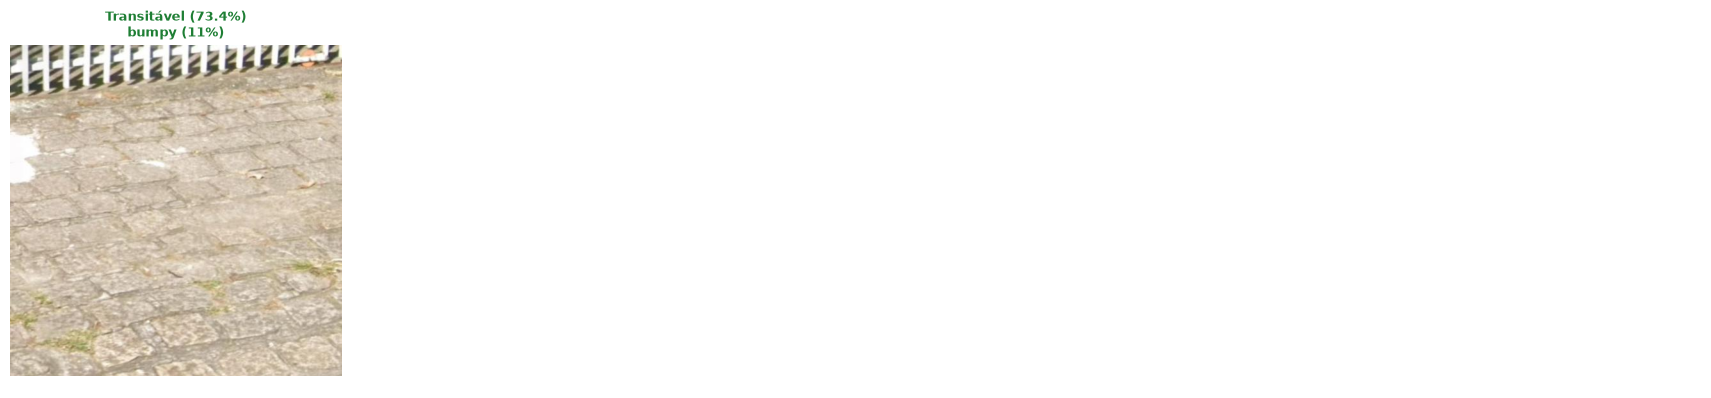

In [3]:
# Escolha qualquer imagem do dataset ou de uma foto avulsa
CAMINHO_IMAGEM = "../data/raw/apx2-bzsou-v4/test/avenida-prefeito-erasto-gaertner__303_2_2_jpg.rf.ef299bced4d8fc871122b1b15d1a5be0.jpg"

# Executa inferência
resultado = pipeline.predict(CAMINHO_IMAGEM)
amostra = resultado[0]

print("=== Resultado da Predição ===")
print(f"Imagem: {amostra['imagem']}")
print(f"Qualidade Predita: {amostra['classe_predita']} (Confiança: {amostra['confianca']*100:.1f}%)")
print(f"Probabilidades por classe: {amostra['probabilidades_classes']}")
print("\nDiagnóstico de Defeitos Físicos (Tagger sem brick):")
for d in amostra.get("principais_defeitos", []):
    print(f" -> {d['tag']:18s}: {d['probabilidade']*100:.1f}%")

# Visualização gráfica da imagem anotada
fig = pipeline.plotar_resultados(resultado, max_imagens=1)
plt.show()

---
## 3. Teste com Lote de Imagens (Lista)

Passagem de uma lista ou conjunto selecionado de caminhos, simulando requisições em batch da aplicação.

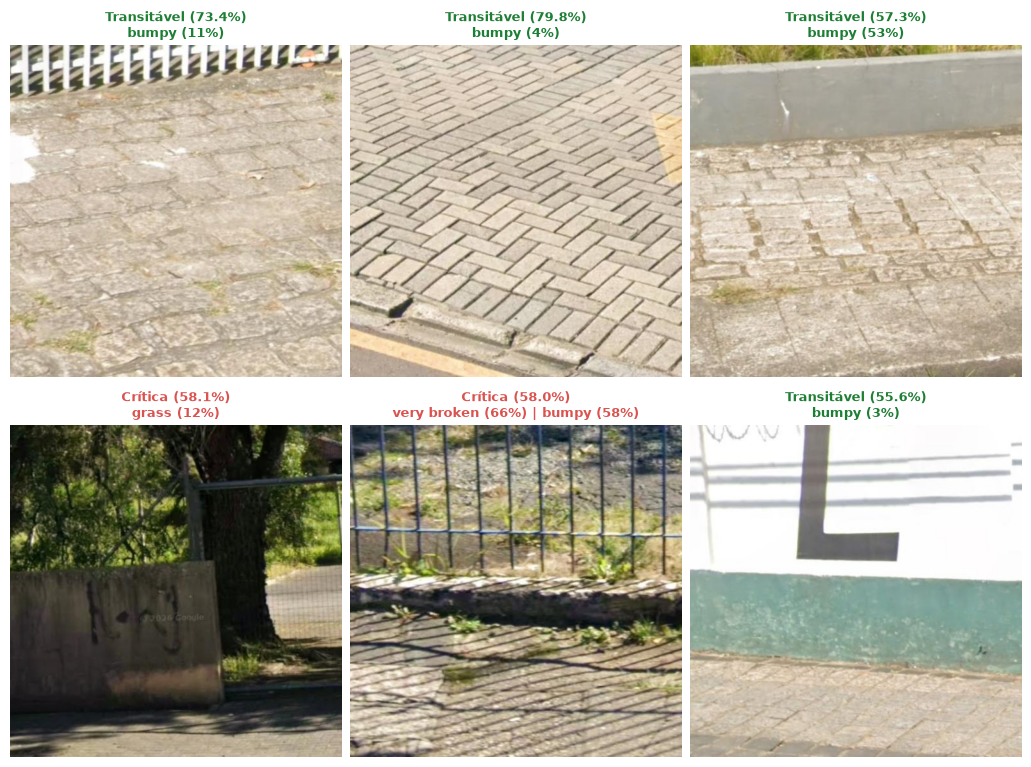

In [4]:
# Seleciona 6 imagens variadas do split de teste
exemplos_teste = sorted(glob.glob("../data/raw/apx2-bzsou-v4/test/*.jpg"))[:6]

# Executa inferência no lote
resultados_lote = pipeline.predict(exemplos_teste)

# Renderiza o grid de diagnóstico com 6 imagens
fig = pipeline.plotar_resultados(resultados_lote, max_imagens=6, colunas=3)
plt.show()

---
## 4. Teste com Diretório Completo (Coleta Street View em Lote)

Você pode apontar uma pasta inteira de imagens. O pipeline varre os arquivos suportados (`.jpg`, `.png`, etc.), processa em lotes otimizados na GPU e pode salvar um `.csv` estruturado consolidado.

In [5]:
PASTA_IMAGENS = "../data/raw/apx2-bzsou-v4/test"
ARQUIVO_SAIDA = "../data/reports/predicoes_inferencia_teste_v4.csv"

# Execução em lote sobre toda a pasta retornando um DataFrame
df_resultados = pipeline.predict(
    PASTA_IMAGENS,
    retornar_df=True,
    salvar_em=ARQUIVO_SAIDA,
    limiar_defeito=0.20,
)

print(f"Total de imagens processadas no diretório: {len(df_resultados)}")
display(df_resultados[["imagem", "classe_predita", "confianca"]].head(10))

[Inferência] Resultados salvos em CSV: '..\data\reports\predicoes_inferencia_teste_v4.csv'
Total de imagens processadas no diretório: 116


,imagem,classe_predita,confianca
0,avenida-prefeito-erasto-gaertner__303_2_2_jpg....,Transitável,0.7340
1,avenida-prefeito-erasto-gaertner__311_3_2_jpg....,Transitável,0.7985
2,avenida-prefeito-erasto-gaertner__314_1_2_jpg....,Transitável,0.5726
3,avenida-prefeito-erasto-gaertner__319_2_1_jpg....,Crítica,0.5815
4,avenida-prefeito-erasto-gaertner__323_4_1_jpg....,Crítica,0.5796
5,avenida-prefeito-erasto-gaertner__331_3_1_jpg....,Transitável,0.5559
6,avenida-prefeito-erasto-gaertner__339_1_3_jpg....,Transitável,0.6949
7,avenida-prefeito-erasto-gaertner__343_1_1_jpg....,Transitável,0.6777
8,avenida-prefeito-erasto-gaertner__374_9_1_jpg....,Transitável,0.6178
9,avenida-prefeito-erasto-gaertner__374_9_2_jpg....,Crítica,0.5096


In [6]:
# Resumo executivo da pasta / via analisada
print("=== DISTRIBUIÇÃO DE QUALIDADE NA PASTA ===")
dist_qualidade = df_resultados["classe_predita"].value_counts(normalize=True) * 100
for classe, pct in dist_qualidade.items():
    total = (df_resultados["classe_predita"] == classe).sum()
    print(f" -> {classe:25s}: {pct:5.1f}% ({total} calçadas)")

# Frequência das principais inconformidades detectadas
print("\n=== TOP 5 DEFEITOS MAIS FREQUENTES (PROBABILIDADE MÉDIA) ===")
cols_tags = [c for c in df_resultados.columns if c.startswith("tags_defeitos.")]
if cols_tags:
    medias_tags = df_resultados[cols_tags].mean().sort_values(ascending=False)
    for col, media in medias_tags.head(5).items():
        tag_nome = col.replace("tags_defeitos.", "")
        print(f" -> {tag_nome:20s}: {media*100:.1f}%")

=== DISTRIBUIÇÃO DE QUALIDADE NA PASTA ===
 -> Transitável              :  56.9% (66 calçadas)
 -> Crítica                  :  43.1% (50 calçadas)

=== TOP 5 DEFEITOS MAIS FREQUENTES (PROBABILIDADE MÉDIA) ===
 -> grass               : 29.2%
 -> bumpy               : 12.0%
 -> very broken         : 11.2%
 -> cracks              : 9.1%
 -> height difference   : 5.0%
